# 04 — How close is PHA to our manual clustering? (label-free)

`02` scored PHA through a hand-built Cell Ontology crosswalk, which assumes both the crosswalk and the
manual labels are ground truth. Here neither is assumed: we treat the manual annotation and PHA as
two alternative partitions of the same cells and ask how they relate geometrically.

Requires `03_qc_and_pha` (QC-passing cells, PHA predictions + 128-d embedding).

**Spaces** (all distances are cosine):
- `pha`: PHA's 128-d embedding. Biased towards PHA's own labels, since it was trained to separate them.
- `pca`: 50 PCs of log-normalised expression (2,000 HVGs, batch-aware). Independent of both
  labelings, so it is the neutral judge.

**Analyses**
1. Cluster tightness: cell → own-centroid distance, silhouette, centroid–centroid distances
2. Label-free agreement: ARI / NMI / homogeneity / completeness, manual vs PHA at each level
3. Does PHA split manual clusters, and is the split real substructure? (permutation test)
4. Suspect cells: closer to another manual cluster, and does PHA agree they're mislabelled?
5. Paper summary table

Glioma malignant states are included here (nothing depends on the ontology).
Outputs → `results/cluster_agreement/`.

In [1]:
import os, sys
from pathlib import Path

# Run from the repo root (found via config.py) so relative paths are stable
_root = Path.cwd()
while not (_root / "config.py").exists():
    _root = _root.parent
os.chdir(_root)
sys.path.insert(0, str(_root))

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score, homogeneity_score,
                             completeness_score, silhouette_samples, silhouette_score)
from sklearn.metrics.pairwise import cosine_distances
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform

from config import DATASETS, RESULTS_DIR, load_counts_adata

QC_DIR = RESULTS_DIR / "qc_pha"
OUT_DIR = RESULTS_DIR / "cluster_agreement"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SPACES = ["pca", "pha"]
PHA_LEVELS = ["azimuth_broad", "azimuth_medium", "azimuth_fine", "final_level_labels"]
N_PCS, N_HVG, KNN_K = 50, 2000, 15
SPLIT_MIN_FRAC, SPLIT_MIN_CELLS, N_PERM = 0.05, 10, 100
rng = np.random.default_rng(0)
pd.set_option("display.max_rows", 200, "display.max_colwidth", 80)


def l2norm(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True).clip(1e-12)


def centroids(Xn, labels):
    """Unit-length centroid per label (mean of L2-normalised vectors, renormalised)."""
    df = pd.DataFrame(Xn).groupby(np.asarray(labels)).mean()
    return pd.DataFrame(l2norm(df.values), index=df.index)

## 0. Load cells and build both spaces

In [3]:
def load(name):
    meta = pd.read_csv(QC_DIR / f"qc_pha_{name}_predictions.csv", index_col=0)
    meta["true_label"] = meta["true_label"].astype(str)
    emb = np.load(QC_DIR / f"qc_pha_{name}_embed.npy")

    a = load_counts_adata(name)[meta.index].copy()
    batch = "patient_id" if "patient_id" in a.obs else "patient"
    sc.pp.normalize_total(a, target_sum=1e4)
    sc.pp.log1p(a)
    sc.pp.highly_variable_genes(a, n_top_genes=N_HVG, batch_key=batch, subset=True)
    sc.pp.scale(a, max_value=10)
    sc.pp.pca(a, n_comps=N_PCS, random_state=0)
    return {"meta": meta, "pca": l2norm(a.obsm["X_pca"]), "pha": l2norm(emb)}


data = {name: load(name) for name in DATASETS}
{name: d["meta"].shape[0] for name, d in data.items()}

/home/hugolab/Documents/Cell2Sentence-HugoLab/panhumanpy-HugoLab/.venv/lib/python3.12/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


/home/hugolab/Documents/Cell2Sentence-HugoLab/panhumanpy-HugoLab/.venv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


/home/hugolab/Documents/Cell2Sentence-HugoLab/panhumanpy-HugoLab/.venv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


/home/hugolab/Documents/Cell2Sentence-HugoLab/panhumanpy-HugoLab/.venv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


/home/hugolab/Documents/Cell2Sentence-HugoLab/panhumanpy-HugoLab/.venv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


/home/hugolab/Documents/Cell2Sentence-HugoLab/panhumanpy-HugoLab/.venv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


/home/hugolab/Documents/Cell2Sentence-HugoLab/panhumanpy-HugoLab/.venv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


{'glioma': 2554,
 'Brain_normal': 2758,
 'Liver_normal': 2797,
 'Lymph_node_normal': 2347,
 'lymphoid': 7099,
 'myeloid': 6181}

## 1. Cluster tightness

**Intra-cluster distance**: cosine distance of each cell to its own manual-cluster centroid.
Tight clusters have small, narrow distributions; a long tail means heterogeneous or mixed clusters.

In [4]:
rows = []
for name, d in data.items():
    m = d["meta"]
    for space in SPACES:
        C = centroids(d[space], m["true_label"])
        own = C.loc[m["true_label"]].values
        dist = 1 - (d[space] * own).sum(axis=1)
        m[f"dist_own_{space}"] = dist
        rows.append(pd.DataFrame({"dataset": name, "space": space,
                                  "true_label": m["true_label"].values, "dist_to_centroid": dist}))
intra = pd.concat(rows, ignore_index=True)

intra_summary = (intra.groupby(["dataset", "true_label", "space"], sort=False)["dist_to_centroid"]
                 .describe(percentiles=[0.25, 0.5, 0.75])[["count", "mean", "25%", "50%", "75%"]]
                 .unstack("space").round(3))
intra_summary.to_csv(OUT_DIR / "intra_cluster_distance.csv")
intra_summary

count  \
space                                                                pca   
dataset           true_label                                               
glioma            CD4/CD8                                          196.0   
                  Pericyte                                         193.0   
                  Endothelial                                      195.0   
                  TAM-MG                                           197.0   
                  TAM-BDM                                          200.0   
                  Oligodendrocyte                                  196.0   
                  MES-like                                         196.0   
                  OPC-like                                         195.0   
                  DC                                                 9.0   
                  OPC                                              195.0   
                  Astrocyte                                        195.0   
                  Neuron                                           196.0   
                  AC-like                                          194.0   
                  NPC-like                                         197.0   
Brain_normal      astrocyte_fibrous_like                           145.0   
                  neuron                                           603.0   
                  smooth_muscle_cell                                21.0   
                  oligodendrocyte                                  819.0   
                  GABAergic_interneuron_SST                         55.0   
                  meningeal_fibroblast                              22.0   
                  venous_endothelial_cell                           43.0   
                  astrocyte_protoplasmic                           267.0   
                  perivascular_fibroblast                           51.0   
                  oligodendrocyte_precursor_cell                    86.0   
                  GABAergic_interneuron                            152.0   
                  capillary_endothelial_cell                       161.0   
                  arterial_endothelial_cell                        107.0   
                  pericyte                                         103.0   
                  oligodendrocyte_ISG_expressing                   123.0   
Liver_normal      venous_endothelial_cell                           45.0   
                  arterial_endothelial_cell                         39.0   
                  pericyte                                          88.0   
                  hepatic_stellate_cell_ACTA2_high                 200.0   
                  hepatocyte                                       907.0   
                  hepatic_stellate_cell_HGF_high                   385.0   
                  cholangiocyte                                    152.0   
                  hepatic_stellate_cell_ACTA2_high_collagen_high    92.0   
                  liver_pericentral_capillary_endothelial_cell     672.0   
                  liver_periportal_capillary_endothelial_cell      190.0   
                  endothelial_cell_proliferating                    27.0   
Lymph_node_normal smooth_muscle_cell                                50.0   
                  venous_endothelial_cell                          167.0   
                  capillary_endothelial_cell                       205.0   
                  arterial_endothelial_cell                         56.0   
                  pericyte                                          87.0   
                  follicular_dendritic_cell                        264.0   
                  LN_fibroblast_collagen_high                      537.0   
                  lymphatic_endothelial_cell                        91.0   
                  LN_stroma_cell                                   663.0   
                  LN_stroma_cell_CHI3L1                            204.0   
                  adipocyte            

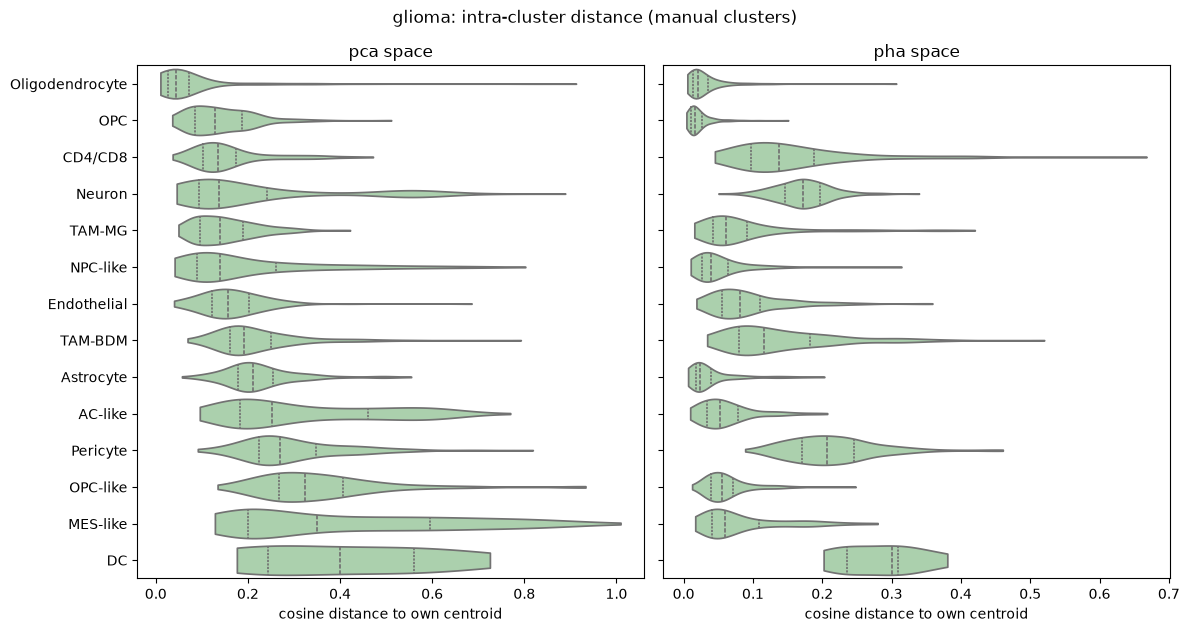

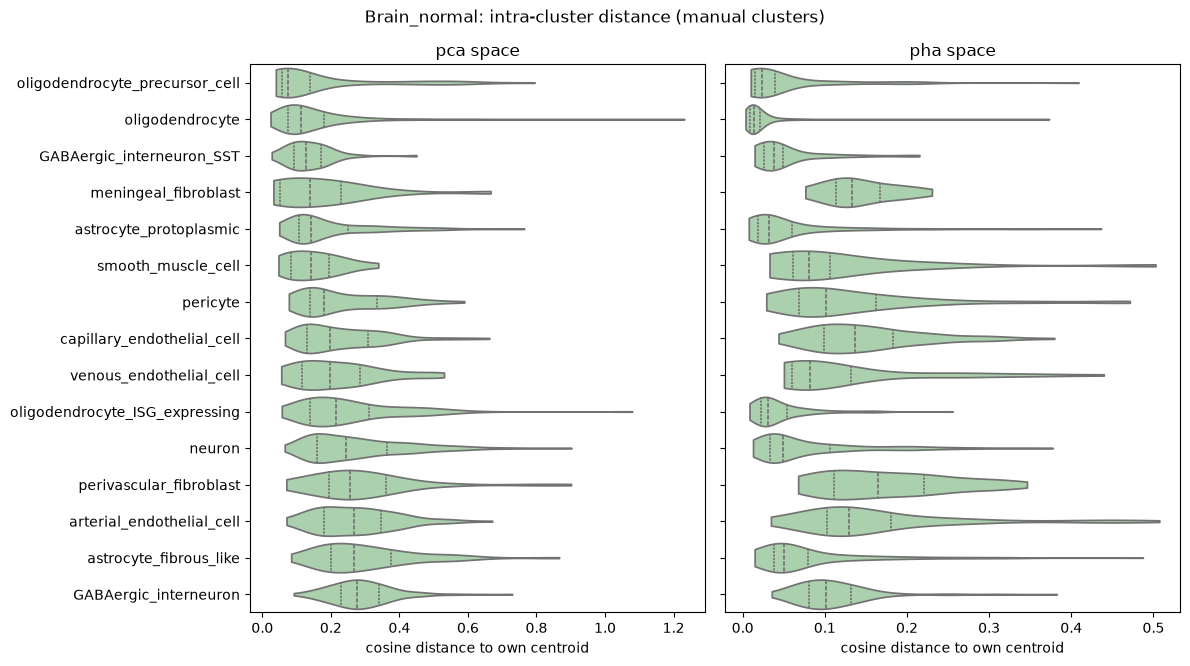

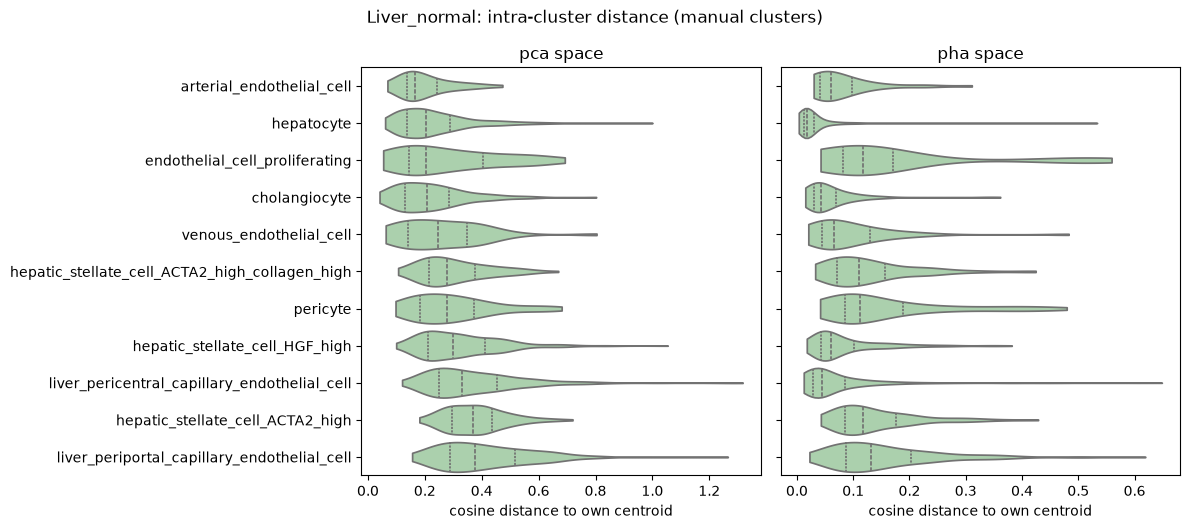

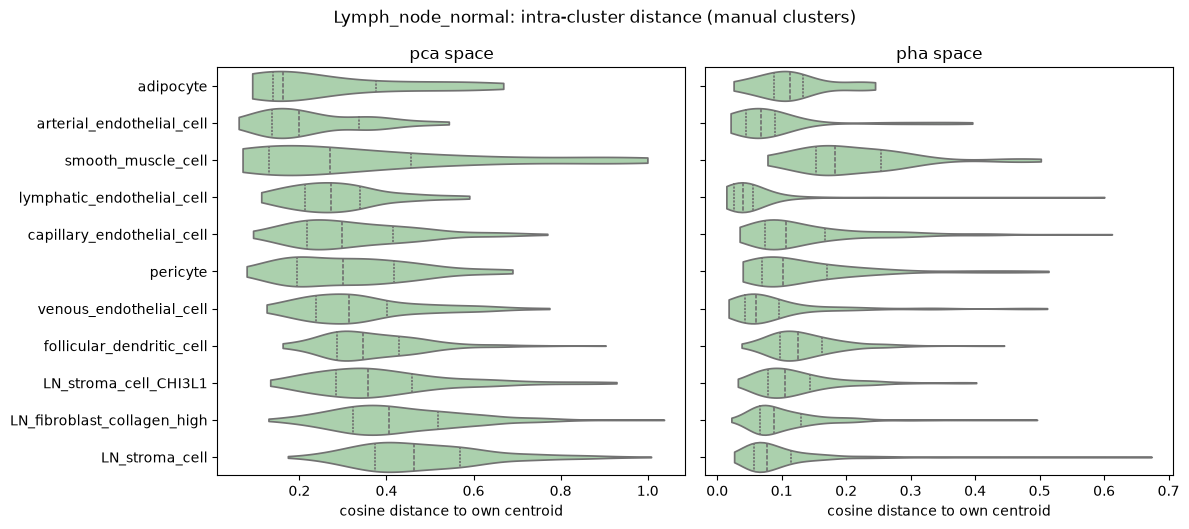

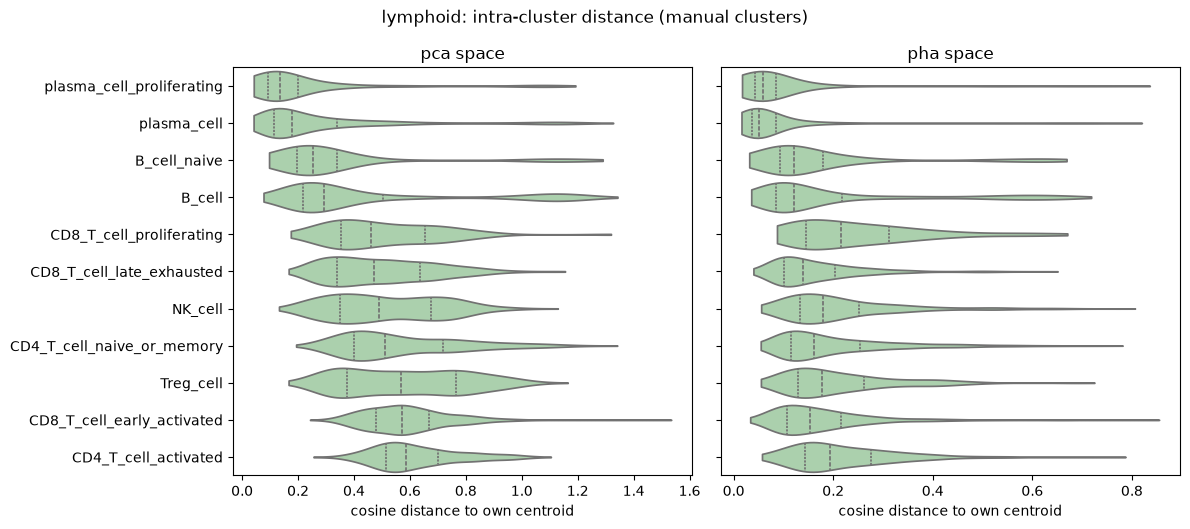

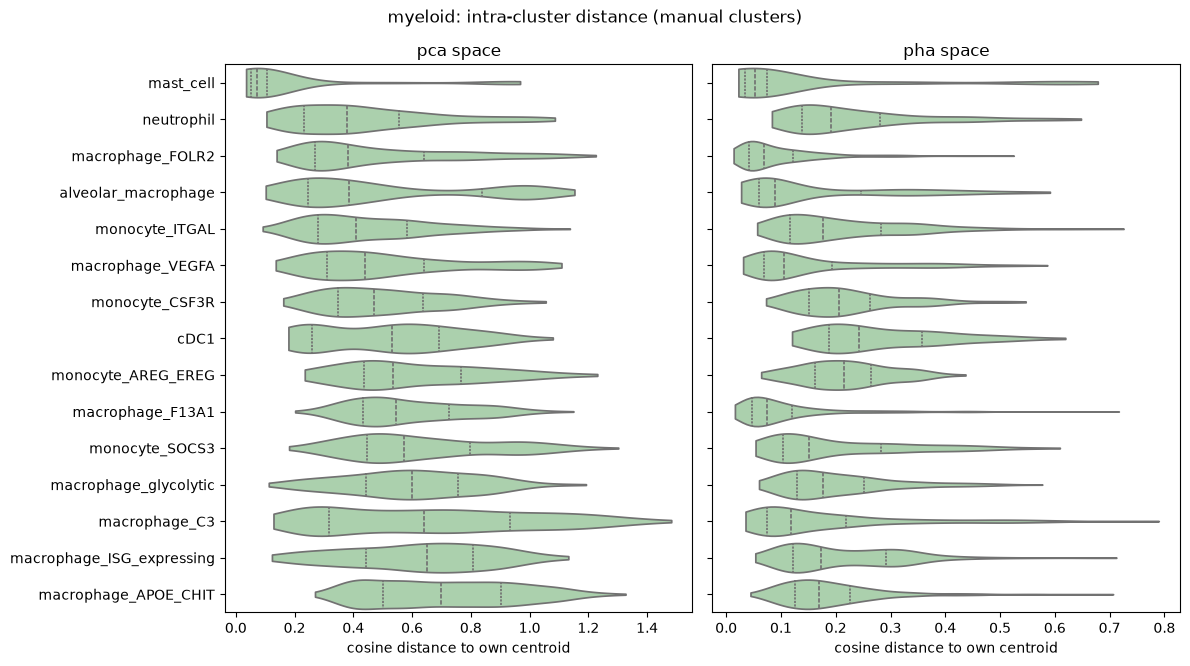

In [5]:
for name in DATASETS:
    d = intra[intra["dataset"] == name]
    order = (d[d["space"] == "pca"].groupby("true_label")["dist_to_centroid"]
             .median().sort_values().index)
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.35 * len(order) + 1.5), sharey=True)
    for ax, space in zip(axes, SPACES):
        sns.violinplot(d[d["space"] == space], y="true_label", x="dist_to_centroid", order=order,
                       cut=0, inner="quartile", density_norm="width", color="#a5d6a7", ax=ax)
        ax.set_title(f"{space} space"); ax.set_xlabel("cosine distance to own centroid"); ax.set_ylabel("")
    fig.suptitle(f"{name}: intra-cluster distance (manual clusters)")
    plt.tight_layout(); plt.savefig(OUT_DIR / f"intra_distance_{name}.png", dpi=150); plt.show()

**Silhouette** (cosine): how much closer each cell is to its own group than to the nearest other group,
in [-1, 1]. Compared for the manual labels vs PHA's `final_level_labels`, in both spaces.
The `pca` column is the fair comparison; in `pha` space PHA has a home advantage.
Also shown: PHA `azimuth_medium` (closer in granularity to our labels). For a like-for-like comparison,
every labeling is scored on the same cells: those whose PHA final label has ≥ 10 cells (PHA emits many
tiny labels; singletons would score 0 by definition). Silhouette still depends on how many groups
there are, so read the gaps alongside `n_groups`.

In [6]:
LABELINGS = [("manual", "true_label"), ("PHA_medium", "azimuth_medium"), ("PHA", "final_level_labels")]

sil_rows, sil_class = [], []
for name, d in data.items():
    m = d["meta"]
    vc = m["final_level_labels"].value_counts()
    mask = m["final_level_labels"].isin(vc[vc >= SPLIT_MIN_CELLS].index).values
    for space in SPACES:
        # per-cluster silhouette of the manual labels uses all cells
        m[f"sil_manual_{space}"] = silhouette_samples(d[space], m["true_label"].values, metric="cosine")
        sil_class.append(m.groupby("true_label")[f"sil_manual_{space}"].mean()
                         .rename(space).to_frame().assign(dataset=name))
        for labeling, col in LABELINGS:
            lbl = m[col].astype(str).values[mask]
            sil_rows.append({"dataset": name, "space": space, "labeling": labeling,
                             "n_groups": len(set(lbl)), "n_cells_scored": int(mask.sum()),
                             "silhouette": silhouette_score(d[space][mask], lbl, metric="cosine")})

sil = pd.DataFrame(sil_rows)
sil_wide = sil.pivot_table(index="dataset", columns=["space", "labeling"], values="silhouette",
                           sort=False).round(3)
for labeling, _ in LABELINGS:
    sil_wide[("n_groups", labeling)] = sil[sil["labeling"] == labeling].groupby("dataset", sort=False)["n_groups"].first()
sil_wide[("n_cells_scored", "")] = sil.groupby("dataset", sort=False)["n_cells_scored"].first()
sil_wide.to_csv(OUT_DIR / "silhouette_by_dataset.csv")
sil_wide

space                pca                      pha                   n_groups  \
labeling          manual PHA_medium    PHA manual PHA_medium    PHA   manual   
dataset                                                                        
glioma             0.372      0.095  0.074  0.253      0.077  0.224       14   
Brain_normal       0.312      0.326  0.336  0.341      0.402  0.527       15   
Liver_normal       0.337      0.276  0.198  0.437      0.563  0.509       11   
Lymph_node_normal  0.173      0.085 -0.025  0.137      0.273  0.247       11   
lymphoid           0.040     -0.005  0.034  0.036      0.126  0.241       11   
myeloid            0.007     -0.016 -0.048 -0.122      0.157  0.264       15   

space                            n_cells_scored  
labeling          PHA_medium PHA                 
dataset                                          
glioma                    17  40           2412  
Brain_normal              13  27           2624  
Liver_normal               7  14           2726  
Lymph_node_normal          6  19           2296  
lymphoid                   7  25           7021  
myeloid                    6  16           6107

In [7]:
sil_per_class = (pd.concat(sil_class).reset_index().rename(columns={"index": "true_label"})
                 .groupby(["dataset", "true_label"], sort=False)[SPACES].first().round(3))
sil_per_class.to_csv(OUT_DIR / "silhouette_per_cluster.csv")
sil_per_class.sort_values("pca")

pca    pha
dataset           true_label                                                  
glioma            DC                                             -0.154 -0.264
                  MES-like                                       -0.098 -0.327
lymphoid          B_cell                                         -0.098 -0.153
glioma            OPC-like                                       -0.097 -0.303
myeloid           macrophage_APOE_CHIT                           -0.072 -0.239
                  monocyte_SOCS3                                 -0.068 -0.138
                  macrophage_ISG_expressing                      -0.062 -0.339
                  macrophage_C3                                  -0.057 -0.259
lymphoid          CD8_T_cell_early_activated                     -0.054 -0.047
myeloid           monocyte_AREG_EREG                             -0.053 -0.253
Brain_normal      oligodendrocyte_ISG_expressing                 -0.041 -0.232
lymphoid          CD8_T_cell_proliferating                       -0.039 -0.184
                  CD4_T_cell_activated                           -0.039 -0.100
myeloid           macrophage_F13A1                               -0.028 -0.004
                  monocyte_CSF3R                                  0.003 -0.128
Liver_normal      liver_periportal_capillary_endothelial_cell     0.015 -0.285
myeloid           macrophage_glycolytic                           0.020 -0.205
lymphoid          CD8_T_cell_late_exhausted                       0.020  0.032
                  Treg_cell                                       0.023  0.027
                  CD4_T_cell_naive_or_memory                      0.048  0.035
                  NK_cell                                         0.084 -0.007
Lymph_node_normal LN_stroma_cell                                  0.087  0.122
Liver_normal      hepatic_stellate_cell_ACTA2_high                0.089 -0.119
glioma            TAM-BDM                                         0.096 -0.085
myeloid           cDC1                                            0.100 -0.036
Brain_normal      GABAergic_interneuron                           0.100  0.012
myeloid           macrophage_VEGFA                                0.101 -0.236
                  monocyte_ITGAL                                  0.115  0.039
Brain_normal      arterial_endothelial_cell                       0.116 -0.052
glioma            AC-like                                         0.118 -0.146
Lymph_node_normal LN_fibroblast_collagen_high                     0.123  0.092
Brain_normal      astrocyte_fibrous_like                          0.124  0.283
myeloid           alveolar_macrophage                             0.130  0.154
                  macrophage_FOLR2                                0.139  0.082
Lymph_node_normal LN_stroma_cell_CHI3L1                           0.142 -0.124
lymphoid          B_cell_naive                                    0.143  0.043
                  plasma_cell                                     0.160  0.250
Lymph_node_normal capillary_endothelial_cell                      0.176  0.017
myeloid           neutrophil                                      0.178  0.069
Lymph_node_normal venous_endothelial_cell                         0.182  0.379
Liver_normal      liver_pericentral_capillary_endothelial_cell    0.206  0.446
                  hepatic_stellate_cell_ACTA2_high_collagen_high  0.227 -0.031
Lymph_node_normal follicular_dendritic_cell                       0.229 -0.001
Brain_normal      perivascular_fibroblast                         0.272 -0.042
                  venous_endothelial_cell                         0.282  0.257
                  capillary_endothelial_cell                      0.282  0.086
Liver_normal      hepatic_stellate_cell_HGF_high                  0.291  0.312
                  endothelial_cell_proliferating                  0.307 -0.183
Brain_normal      pericyte                                        0.312  0.218
Lymph_node_normal smooth_muscle_cell   

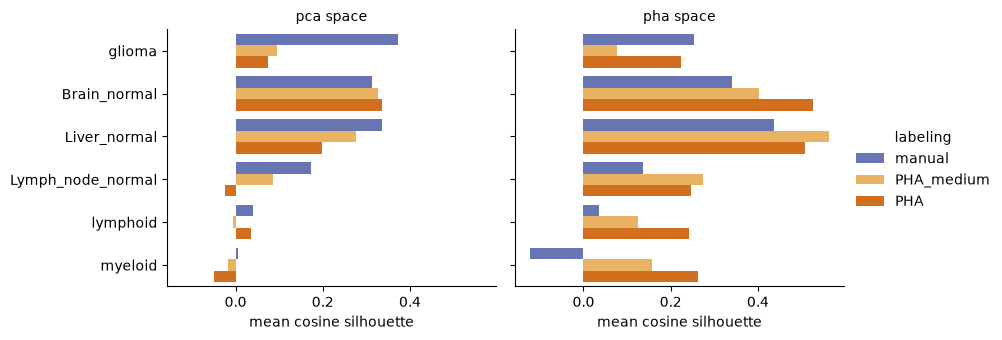

In [8]:
g = sns.catplot(sil, x="silhouette", y="dataset", hue="labeling", col="space", kind="bar",
                height=3.5, aspect=1.3, palette=["#5c6bc0", "#ffb74d", "#ef6c00"])
g.set_titles("{col_name} space"); g.set_axis_labels("mean cosine silhouette", "")
plt.savefig(OUT_DIR / "silhouette_manual_vs_pha.png", dpi=150, bbox_inches="tight"); plt.show()

**Centroid–centroid distances** between manual clusters (PCA space). Pairs with small distance are
the ones most likely to be confused / over-split in the manual annotation.

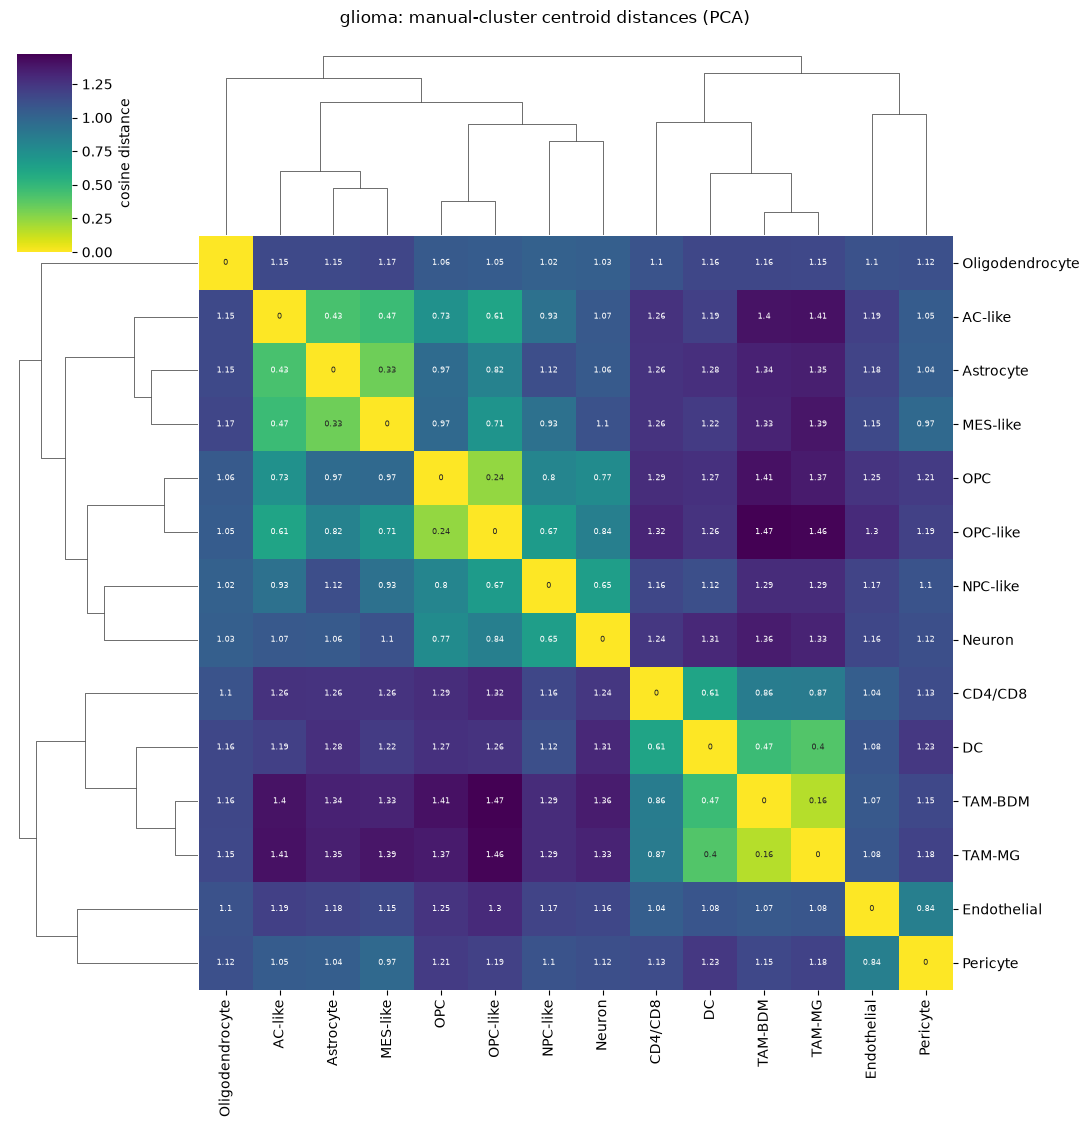

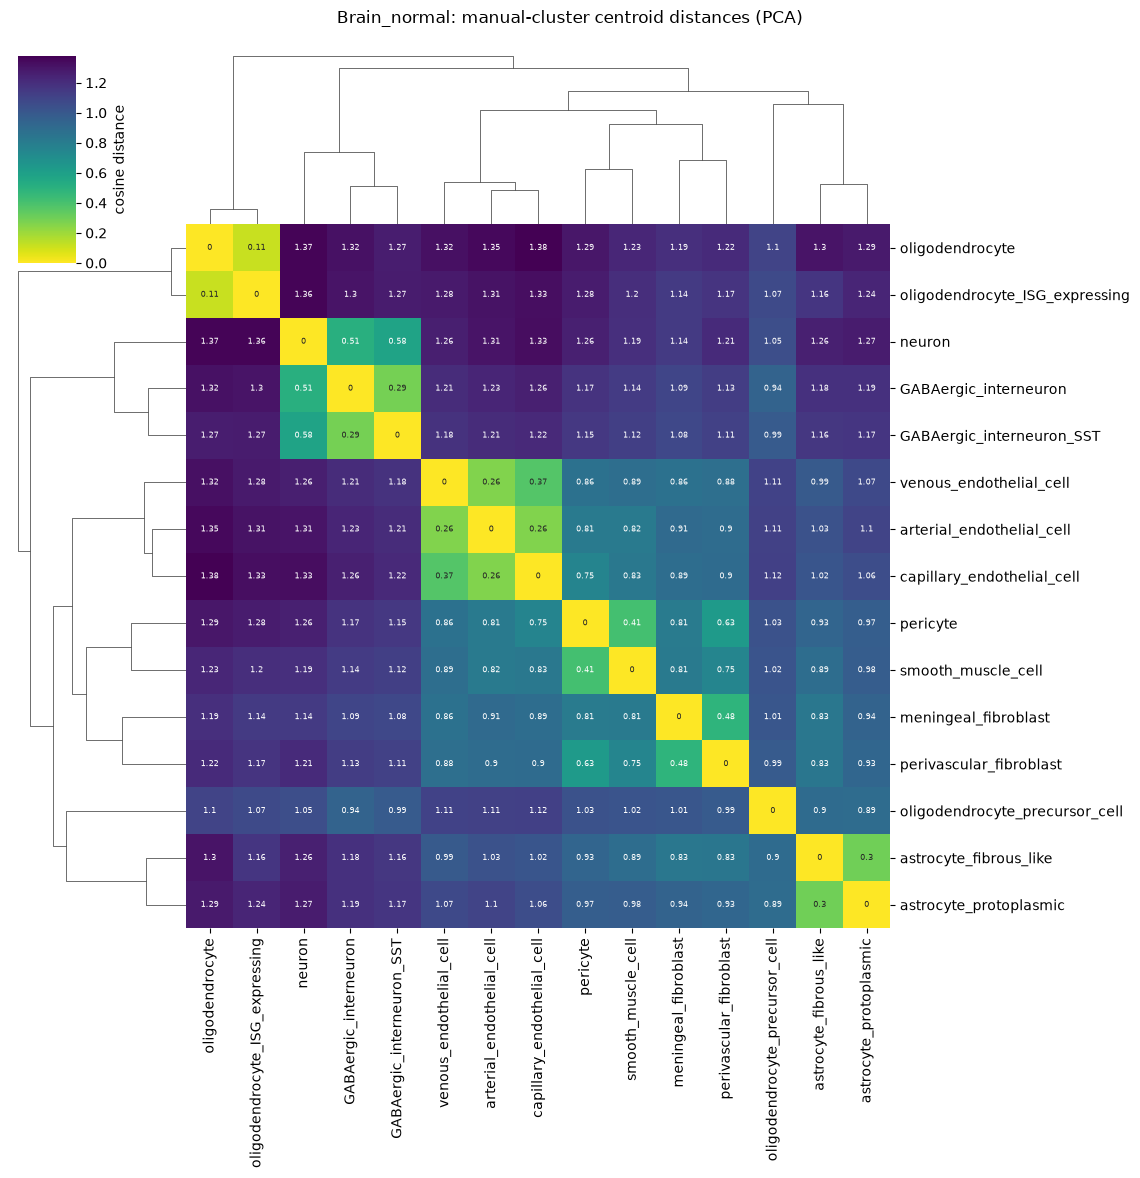

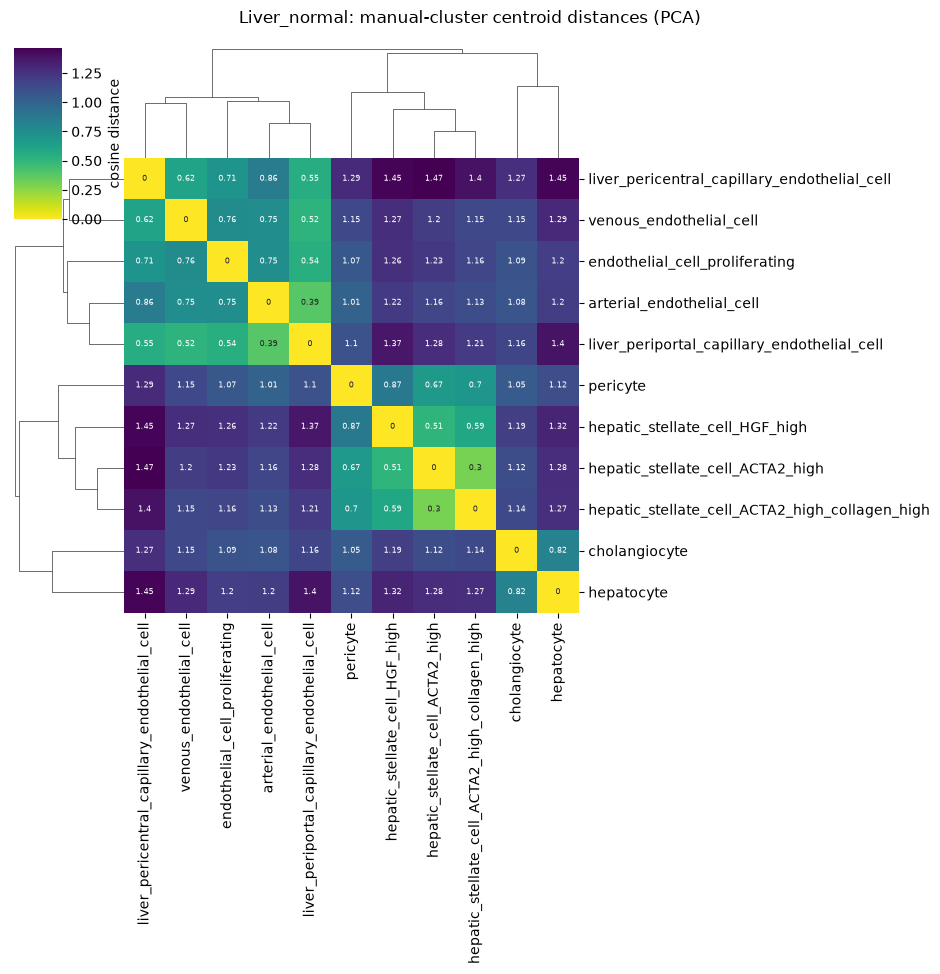

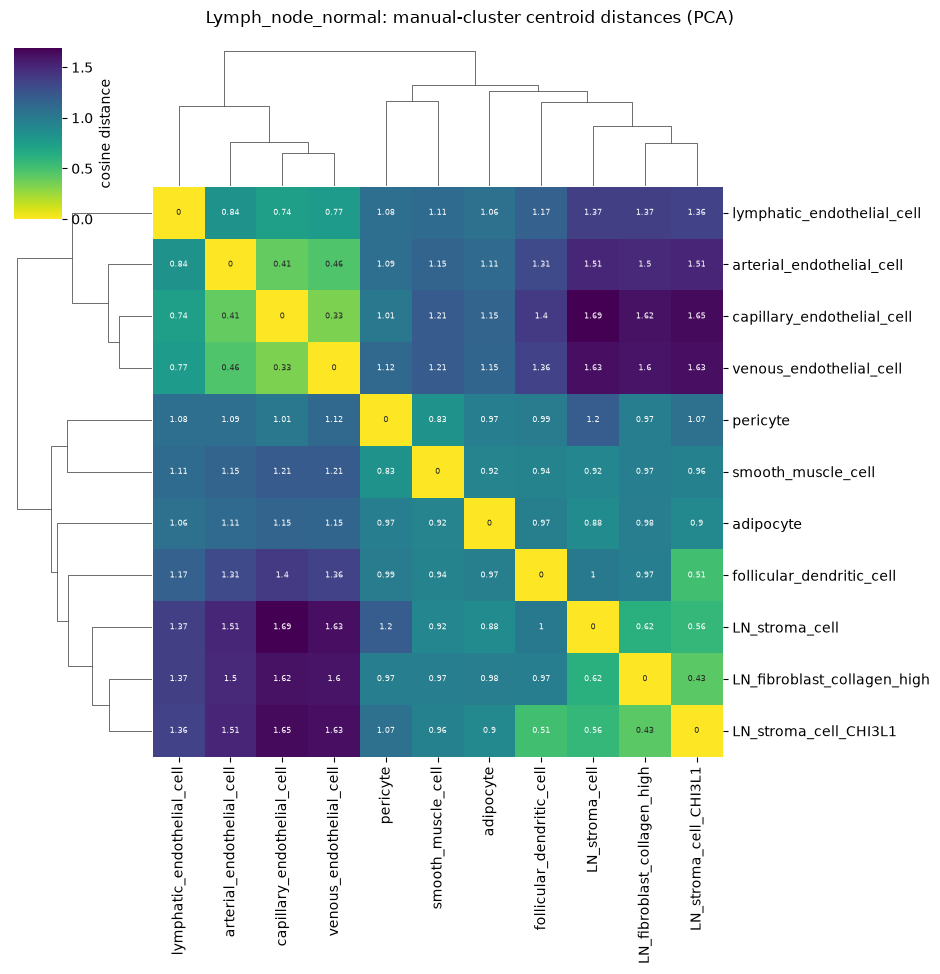

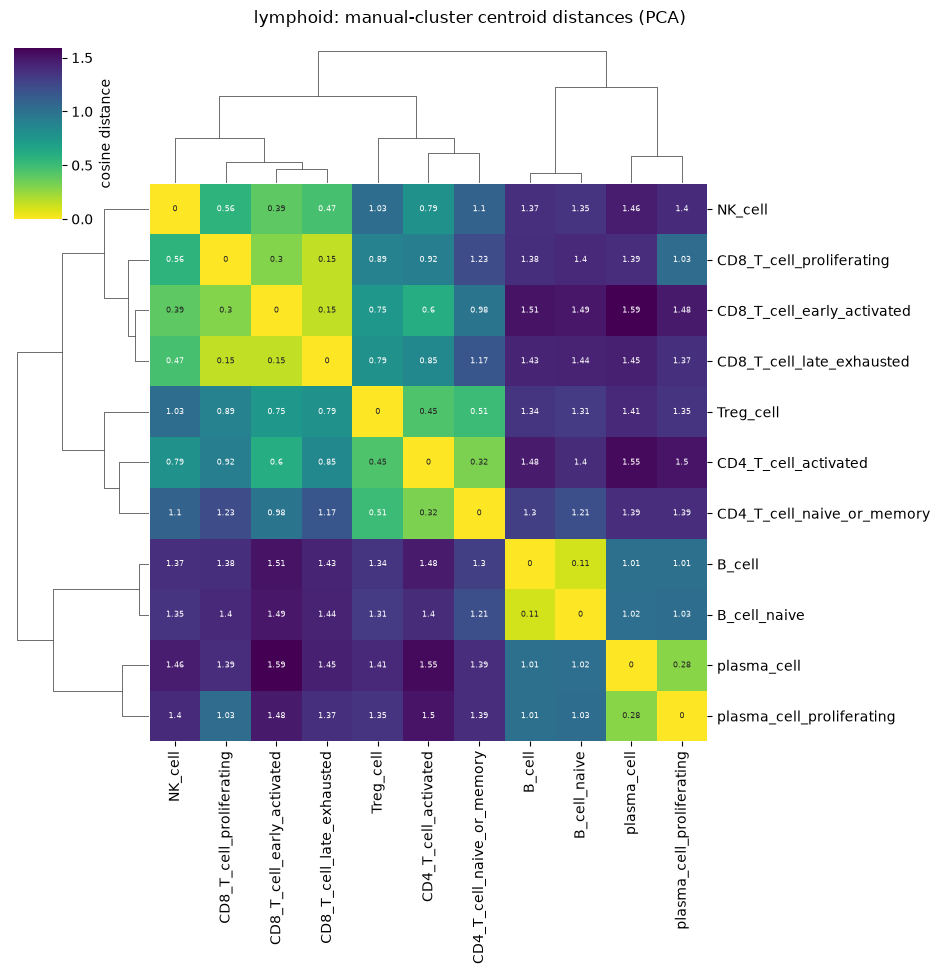

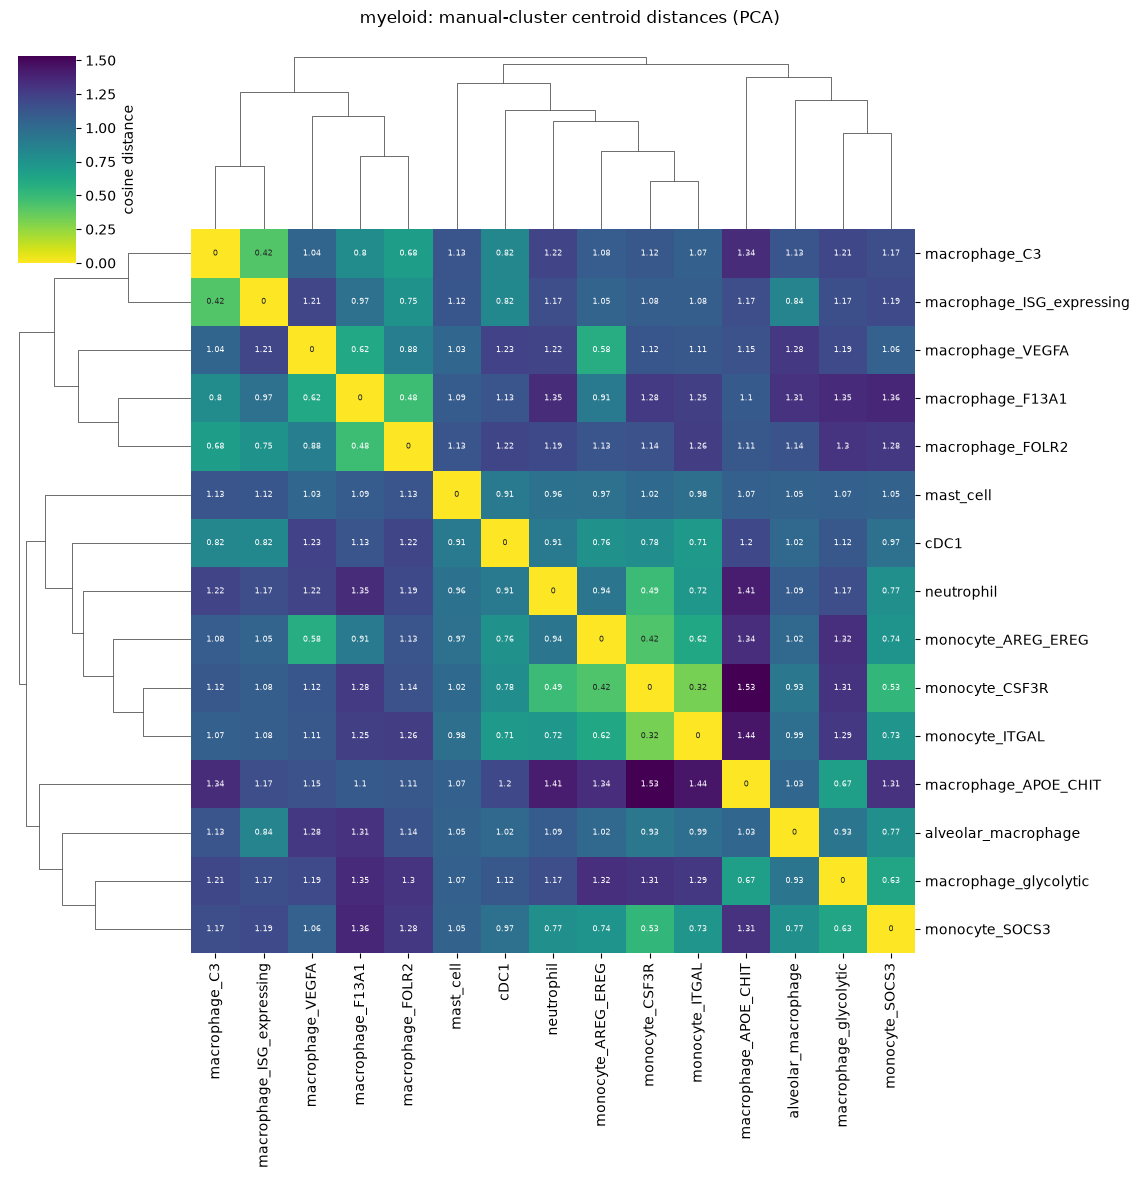

In [9]:
for name, d in data.items():
    C = centroids(d["pca"], d["meta"]["true_label"])
    D = pd.DataFrame(cosine_distances(C.values), index=C.index, columns=C.index)
    D.round(3).to_csv(OUT_DIR / f"centroid_distance_{name}.csv")
    Z = linkage(squareform(D.values, checks=False), method="average")
    cg = sns.clustermap(D, row_linkage=Z, col_linkage=Z, cmap="viridis_r", annot=D.round(2), fmt="g", annot_kws={"size": 6},
                        figsize=(0.5 * len(D) + 4, 0.5 * len(D) + 4),
                        cbar_kws={"label": "cosine distance"})
    cg.fig.suptitle(f"{name}: manual-cluster centroid distances (PCA)", y=1.02)
    cg.savefig(OUT_DIR / f"centroid_distance_{name}.png", dpi=150); plt.show()

## 2. Label-free agreement

Manual labels as `labels_true`, PHA as `labels_pred`:
- **ARI / NMI**: overall agreement of the two partitions (chance-corrected / information-based)
- **homogeneity**: each PHA label contains cells from only one manual cluster
- **completeness**: each manual cluster falls into a single PHA label

High homogeneity + low completeness ⇒ PHA *splits* our clusters (finer); the reverse ⇒ PHA *merges* them.
The `shuffled` row is a null (manual labels permuted) and should be ≈ 0 for ARI.

In [10]:
agree_rows = []
for name, d in data.items():
    m = d["meta"]
    shuffled = rng.permutation(m["true_label"].values)
    for level in PHA_LEVELS + ["shuffled"]:
        pred = m["final_level_labels"].values if level == "shuffled" else m[level].astype(str).values
        true = shuffled if level == "shuffled" else m["true_label"].values
        agree_rows.append({"dataset": name, "pha_level": level, "n_pha_labels": len(set(pred)),
                           "ARI": adjusted_rand_score(true, pred),
                           "NMI": normalized_mutual_info_score(true, pred),
                           "homogeneity": homogeneity_score(true, pred),
                           "completeness": completeness_score(true, pred)})
agree = pd.DataFrame(agree_rows).set_index(["dataset", "pha_level"]).round(3)
agree.to_csv(OUT_DIR / "partition_agreement.csv")
agree

n_pha_labels    ARI    NMI  homogeneity  \
dataset           pha_level                                                     
glioma            azimuth_broad                  8  0.241  0.495        0.425   
                  azimuth_medium                24  0.243  0.569        0.532   
                  azimuth_fine                  61  0.183  0.528        0.554   
                  final_level_labels            94  0.357  0.626        0.738   
                  shuffled                      94  0.000  0.062        0.073   
Brain_normal      azimuth_broad                  9  0.440  0.528        0.437   
                  azimuth_medium                19  0.600  0.616        0.551   
                  azimuth_fine                  40  0.631  0.642        0.653   
                  final_level_labels            75  0.730  0.710        0.789   
                  shuffled                      75  0.007  0.056        0.062   
Liver_normal      azimuth_broad                  8  0.636  0.641        0.547   
                  azimuth_medium                14  0.638  0.642        0.554   
                  azimuth_fine                  36  0.722  0.632        0.678   
                  final_level_labels            50  0.739  0.693        0.691   
                  shuffled                      50  0.003  0.031        0.031   
Lymph_node_normal azimuth_broad                  7  0.267  0.419        0.328   
                  azimuth_medium                10  0.268  0.428        0.338   
                  azimuth_fine                  27  0.287  0.466        0.467   
                  final_level_labels            38  0.313  0.495        0.517   
                  shuffled                      38 -0.002  0.032        0.034   
lymphoid          azimuth_broad                  6  0.008  0.016        0.009   
                  azimuth_medium                17  0.225  0.335        0.256   
                  azimuth_fine                  40  0.371  0.397        0.409   
                  final_level_labels            55  0.387  0.409        0.449   
                  shuffled                      55 -0.000  0.013        0.015   
myeloid           azimuth_broad                  4  0.002  0.013        0.007   
                  azimuth_medium                13  0.066  0.149        0.102   
                  azimuth_fine                  26  0.083  0.218        0.187   
                  final_level_labels            46  0.082  0.228        0.210   
                  shuffled                      46  0.001  0.016        0.015   

                                      completeness  
dataset           pha_level                         
glioma            azimuth_broad              0.591  
                  azimuth_medium             0.612  
                  azimuth_fine               0.505  
                  final_level_labels         0.544  
                  shuffled                   0.054  
Brain_normal      azimuth_broad              0.668  
                  azimuth_medium             0.700  
                  azimuth_fine               0.631  
                  final_level_labels         0.646  
                  shuffled                   0.051  
Liver_normal      azimuth_broad              0.775  
                  azimuth_medium             0.764  
                  azimuth_fine               0.592  
                  final_level_labels         0.696  
                  shuffled                   0.031  
Lymph_node_normal azimuth_broad              0.579  
                  azimuth_medium             0.581  
                  azimuth_fine               0.466  
                  final_level_labels         0.475  
                  shuffled                   0.031  
lymphoid          azimuth_broad              0.054  
                  azimuth_medium             0.486  
                  azimuth_fine               0.386  
                  final_level_labels         0.376  
                  shuffled                   0.012  
myeloid       

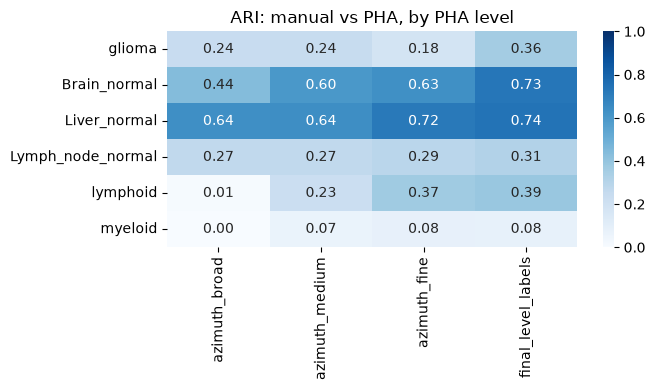

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(agree.drop("shuffled", level="pha_level")["ARI"].unstack("pha_level")[PHA_LEVELS]
            .reindex(list(DATASETS)), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("ARI: manual vs PHA, by PHA level"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(OUT_DIR / "ari_heatmap.png", dpi=150); plt.show()

## 3. Does PHA split manual clusters — and is the split real?

For each manual cluster: PHA labels covering ≥ 5% of its cells, and the normalised entropy of PHA labels
(0 = one label, 1 = evenly spread). Then, within the cluster only and in **PCA space**, the silhouette
of PHA's sub-groups (≥ 10 cells each) vs a null of 100 label permutations.
A large z / small p ⇒ PHA's sub-labels pick out genuine expression substructure inside our cluster
(candidate sub-clusters); z ≈ 0 ⇒ PHA's split is noise relative to expression.

In [12]:
def split_stats(Xn, pha):
    vc = pd.Series(pha).value_counts()
    p = (vc / vc.sum()).values
    out = {"n": len(pha), "n_pha_labels_5pct": int((p >= SPLIT_MIN_FRAC).sum()),
           "entropy_norm": float(-(p * np.log(p)).sum() / np.log(len(p))) if len(p) > 1 else 0.0,
           "top_pha": ", ".join(f"{k} ({100 * v / vc.sum():.0f}%)" for k, v in vc.head(3).items())}
    keep_lbl = vc[vc >= SPLIT_MIN_CELLS].index
    mask = np.isin(pha, keep_lbl)
    if len(keep_lbl) < 2:
        return {**out, "sub_silhouette": np.nan, "null_mean": np.nan, "z": np.nan, "p_perm": np.nan}
    D = cosine_distances(Xn[mask])
    lbl = np.asarray(pha)[mask]
    obs = silhouette_score(D, lbl, metric="precomputed")
    null = np.array([silhouette_score(D, rng.permutation(lbl), metric="precomputed")
                     for _ in range(N_PERM)])
    return {**out, "sub_silhouette": obs, "null_mean": null.mean(),
            "z": (obs - null.mean()) / null.std(ddof=1),
            "p_perm": (1 + (null >= obs).sum()) / (N_PERM + 1)}


split_rows = []
for name, d in data.items():
    m = d["meta"]
    for lbl, idx in m.groupby("true_label").indices.items():
        split_rows.append({"dataset": name, "true_label": lbl,
                           **split_stats(d["pca"][idx], m["final_level_labels"].values[idx])})
splits = pd.DataFrame(split_rows).set_index(["dataset", "true_label"])
splits.round(3).to_csv(OUT_DIR / "pha_splits_within_clusters.csv")
splits.round(3).sort_values("z", ascending=False)

n  \
dataset           true_label                                             
Brain_normal      GABAergic_interneuron                            152   
glioma            Astrocyte                                        195   
                  Neuron                                           196   
                  Pericyte                                         193   
lymphoid          plasma_cell                                     1467   
Brain_normal      astrocyte_fibrous_like                           145   
myeloid           cDC1                                              89   
lymphoid          CD8_T_cell_proliferating                          87   
myeloid           alveolar_macrophage                              303   
lymphoid          Treg_cell                                        389   
Brain_normal      arterial_endothelial_cell                        107   
                  astrocyte_protoplasmic                           267   
Liver_normal      liver_periportal_capillary_endothelial_cell      190   
                  hepatocyte                                       907   
Brain_normal      neuron                                           603   
myeloid           monocyte_SOCS3                                   386   
Lymph_node_normal venous_endothelial_cell                          167   
glioma            Oligodendrocyte                                  196   
                  MES-like                                         196   
myeloid           macrophage_F13A1                                 794   
Liver_normal      liver_pericentral_capillary_endothelial_cell     672   
Lymph_node_normal capillary_endothelial_cell                       205   
Liver_normal      pericyte                                          88   
glioma            CD4/CD8                                          196   
myeloid           monocyte_CSF3R                                   238   
                  macrophage_ISG_expressing                        286   
lymphoid          B_cell                                           978   
glioma            AC-like                                          194   
                  TAM-BDM                                          200   
lymphoid          NK_cell                                          367   
Liver_normal      venous_endothelial_cell                           45   
                  hepatic_stellate_cell_ACTA2_high                 200   
Lymph_node_normal follicular_dendritic_cell                        264   
myeloid           neutrophil                                       214   
lymphoid          CD8_T_cell_late_exhausted                        579   
Liver_normal      cholangiocyte                                    152   
myeloid           macrophage_glycolytic                            364   
                  monocyte_ITGAL                                   326   
Lymph_node_normal LN_stroma_cell                                   663   
glioma            TAM-MG                                           197   
Lymph_node_normal LN_stroma_cell_CHI3L1                            204   
glioma            OPC                                              195   
                  Endothelial                                      195   
myeloid           monocyte_AREG_EREG                               133   
glioma            NPC-like                                         197   
Brain_normal      capillary_endothelial_cell                       161   
lymphoid          CD8_T_cell_early_activated                      1024   
glioma            OPC-like                                         195   
lymphoid          CD4_T_cell_naive_or_memory                      1270   
myeloid           macrophage_FOLR2                                 432   
                  macrophage_C3                                    334   
Lymph_node_normal LN_fibroblast_collagen_high                      537   
myeloid           macrophage_VEGFA                                 322   

## 4. Suspect cells

In PCA space, `margin = d(own centroid) − min d(other centroid)`; **suspect** if margin > 0 (the cell is
closer to another manual cluster than to its own). `knn_purity` = fraction of the 15 nearest
neighbours (cosine) sharing the cell's manual label.

PHA evidence, without the ontology: each manual cluster's *modal* PHA label is its PHA "signature".
- `pha_disagrees`: the cell's PHA label ≠ its own cluster's modal PHA label
- `pha_supports_switch`: the cell's PHA label = the modal PHA label of its **nearest other** cluster
  (and that differs from its own cluster's). Suspect + supports_switch is the strongest mislabel signal.

In [13]:
susp_rows = []
for name, d in data.items():
    m = d["meta"]
    X, labels = d["pca"], m["true_label"].values
    C = centroids(X, labels)
    S = X @ C.values.T                                   # cosine similarity to each centroid
    own_i = C.index.get_indexer(labels)
    d_all = 1 - S
    d_own = d_all[np.arange(len(m)), own_i]
    d_other = d_all.copy(); d_other[np.arange(len(m)), own_i] = np.inf
    near_i = d_other.argmin(axis=1)

    nn = NearestNeighbors(n_neighbors=KNN_K + 1, metric="cosine").fit(X)
    nbr = nn.kneighbors(X, return_distance=False)[:, 1:]
    knn_purity = (labels[nbr] == labels[:, None]).mean(axis=1)

    mode_pha = m.groupby("true_label")["final_level_labels"].agg(lambda s: s.value_counts().index[0])
    own_mode = mode_pha.loc[labels].values
    near_label = C.index.values[near_i]
    near_mode = mode_pha.loc[near_label].values
    pha = m["final_level_labels"].values

    susp_rows.append(pd.DataFrame({
        "dataset": name, "true_label": labels, "nearest_other_cluster": near_label,
        "margin": d_own - d_other.min(axis=1), "knn_purity": knn_purity,
        "pha_label": pha, "pha_conf": m["final_level_confidence"].values,
        "own_cluster_modal_pha": own_mode, "nearest_cluster_modal_pha": near_mode,
        "pha_disagrees": pha != own_mode,
        "pha_supports_switch": (pha == near_mode) & (near_mode != own_mode),
    }, index=m.index))

susp = pd.concat(susp_rows)
susp["suspect"] = susp["margin"] > 0
susp["strong_suspect"] = susp["suspect"] & susp["pha_supports_switch"]
susp.to_csv(OUT_DIR / "per_cell_suspect.csv")
susp[susp["suspect"]].sort_values("margin", ascending=False).to_csv(OUT_DIR / "suspect_cells.csv")
print(f"{susp['suspect'].sum():,} suspect cells ({100 * susp['suspect'].mean():.1f}%), "
      f"{susp['strong_suspect'].sum():,} with PHA supporting the switch")

5,946 suspect cells (25.1%), 1,142 with PHA supporting the switch


Is PHA disagreement concentrated on geometrically suspect cells? If PHA tracks real biology, cells that
sit closer to another cluster should be much more likely to get that cluster's PHA signature.

In [14]:
(susp.groupby(["dataset", "suspect"])[["pha_disagrees", "pha_supports_switch", "pha_conf", "knn_purity"]]
 .mean().mul([100, 100, 1, 1]).round(2)
 .rename(columns={"pha_disagrees": "pha_disagrees_%", "pha_supports_switch": "pha_supports_switch_%",
                  "pha_conf": "mean_pha_conf", "knn_purity": "mean_knn_purity"}))

pha_disagrees_%  pha_supports_switch_%  \
dataset           suspect                                           
Brain_normal      False              23.86                   2.91   
                  True               50.81                  18.38   
Liver_normal      False              12.86                   2.57   
                  True               32.68                  12.42   
Lymph_node_normal False              29.95                   6.33   
                  True               37.91                   6.14   
glioma            False              51.17                   6.73   
                  True               74.07                  30.64   
lymphoid          False              39.51                   3.71   
                  True               79.13                  25.09   
myeloid           False              44.67                   8.39   
                  True               59.15                  14.22   

                           mean_pha_conf  mean_knn_purity  
dataset           suspect                                  
Brain_normal      False             0.88             0.95  
                  True              0.81             0.47  
Liver_normal      False             0.92             0.95  
                  True              0.87             0.46  
Lymph_node_normal False             0.81             0.89  
                  True              0.79             0.43  
glioma            False             0.76             0.92  
                  True              0.68             0.37  
lymphoid          False             0.86             0.79  
                  True              0.78             0.25  
myeloid           False             0.85             0.74  
                  True              0.86             0.28

In [15]:
susp_by_cluster = (susp.groupby(["dataset", "true_label"], sort=False)
                   .agg(n=("suspect", "size"),
                        suspect_pct=("suspect", lambda s: 100 * s.mean()),
                        strong_suspect_pct=("strong_suspect", lambda s: 100 * s.mean()),
                        median_knn_purity=("knn_purity", "median"),
                        top_nearest_other=("nearest_other_cluster",
                                           lambda s: s.value_counts().index[0]))
                   .round(2))
susp_by_cluster.to_csv(OUT_DIR / "suspect_by_cluster.csv")
susp_by_cluster.sort_values("suspect_pct", ascending=False)

n  \
dataset           true_label                                             
myeloid           macrophage_ISG_expressing                        286   
lymphoid          CD8_T_cell_early_activated                      1024   
                  CD8_T_cell_proliferating                          87   
myeloid           macrophage_APOE_CHIT                            1890   
                  monocyte_SOCS3                                   386   
                  macrophage_C3                                    334   
lymphoid          CD4_T_cell_activated                             527   
myeloid           monocyte_AREG_EREG                               133   
lymphoid          Treg_cell                                        389   
myeloid           macrophage_glycolytic                            364   
                  monocyte_CSF3R                                   238   
                  macrophage_F13A1                                 794   
lymphoid          CD8_T_cell_late_exhausted                        579   
myeloid           cDC1                                              89   
lymphoid          B_cell_naive                                     179   
                  CD4_T_cell_naive_or_memory                      1270   
                  NK_cell                                          367   
glioma            MES-like                                         196   
lymphoid          B_cell                                           978   
myeloid           monocyte_ITGAL                                   326   
                  neutrophil                                       214   
                  macrophage_VEGFA                                 322   
                  alveolar_macrophage                              303   
glioma            OPC-like                                         195   
                  AC-like                                          194   
myeloid           macrophage_FOLR2                                 432   
glioma            DC                                                 9   
Brain_normal      oligodendrocyte_ISG_expressing                   123   
Lymph_node_normal LN_stroma_cell                                   663   
glioma            Astrocyte                                        195   
                  Neuron                                           196   
Brain_normal      arterial_endothelial_cell                        107   
lymphoid          plasma_cell                                     1467   
Lymph_node_normal LN_fibroblast_collagen_high                      537   
Liver_normal      hepatic_stellate_cell_ACTA2_high                 200   
glioma            TAM-MG                                           197   
Lymph_node_normal follicular_dendritic_cell                        264   
lymphoid          plasma_cell_proliferating                        232   
Lymph_node_normal smooth_muscle_cell                                50   
Brain_normal      astrocyte_protoplasmic                           267   
Liver_normal      endothelial_cell_proliferating                    27   
Lymph_node_normal LN_stroma_cell_CHI3L1                            204   
Brain_normal      astrocyte_fibrous_like                           145   
myeloid           mast_cell                                         70   
Liver_normal      liver_periportal_capillary_endothelial_cell      190   
                  liver_pericentral_capillary_endothelial_cell     672   
Brain_normal      capillary_endothelial_cell                       161   
glioma            TAM-BDM                                          200   
Brain_normal      venous_endothelial_cell                           43   
                  oligodendrocyte                                  819   
Liver_normal      hepatic_stellate_cell_HGF_high                   385   
glioma            NPC-like                                         197   
Lymph_node_normal capillary_endothelial_cell                       205   

Where do strong suspects want to move? (manual label → nearest other cluster, counts)

In [16]:
moves = (susp[susp["strong_suspect"]].groupby(["dataset", "true_label", "nearest_other_cluster"])
         .size().rename("n_strong_suspects").sort_values(ascending=False))
moves.to_csv(OUT_DIR / "strong_suspect_moves.csv")
moves.head(30)

dataset       true_label                  nearest_other_cluster     
lymphoid      CD4_T_cell_naive_or_memory  CD4_T_cell_activated          81
              CD8_T_cell_early_activated  CD8_T_cell_late_exhausted     79
myeloid       macrophage_APOE_CHIT        macrophage_glycolytic         42
lymphoid      CD4_T_cell_naive_or_memory  Treg_cell                     40
              CD4_T_cell_activated        CD4_T_cell_naive_or_memory    39
              CD8_T_cell_early_activated  CD4_T_cell_activated          35
              B_cell                      plasma_cell                   32
myeloid       macrophage_APOE_CHIT        monocyte_SOCS3                31
lymphoid      CD8_T_cell_late_exhausted   CD8_T_cell_early_activated    29
              Treg_cell                   CD4_T_cell_activated          25
myeloid       alveolar_macrophage         macrophage_FOLR2              23
              macrophage_glycolytic       macrophage_FOLR2              23
              macrophage_APOE_C

## 5. Paper summary
One row per dataset. `sil_*`: mean cosine silhouette; `ARI`/`NMI`: manual vs PHA `final_level_labels`.

In [17]:
fl = agree.xs("final_level_labels", level="pha_level")
paper = pd.DataFrame({
    "n_cells": susp.groupby("dataset", sort=False).size(),
    "n_manual_clusters": susp.groupby("dataset", sort=False)["true_label"].nunique(),
    "n_pha_labels": fl["n_pha_labels"],
    "median_intra_dist_pca": intra[intra["space"] == "pca"].groupby("dataset", sort=False)["dist_to_centroid"].median(),
    "median_intra_dist_pha": intra[intra["space"] == "pha"].groupby("dataset", sort=False)["dist_to_centroid"].median(),
    "sil_manual_pca": sil_wide[("pca", "manual")], "sil_PHA_pca": sil_wide[("pca", "PHA")],
    "sil_manual_pha": sil_wide[("pha", "manual")], "sil_PHA_pha": sil_wide[("pha", "PHA")],
    "ARI": fl["ARI"], "NMI": fl["NMI"],
    "homogeneity": fl["homogeneity"], "completeness": fl["completeness"],
    "suspect_%": susp.groupby("dataset", sort=False)["suspect"].mean() * 100,
    "strong_suspect_%": susp.groupby("dataset", sort=False)["strong_suspect"].mean() * 100,
    "clusters_with_real_PHA_split": splits.groupby(level="dataset", sort=False)
        .apply(lambda s: int(((s["p_perm"] < 0.05) & (s["z"] > 3)).sum())),
    "median_pha_conf": susp.groupby("dataset", sort=False)["pha_conf"].median(),
}).reindex(list(DATASETS)).round(3)
paper.to_csv(OUT_DIR / "paper_summary.csv")
paper.T

dataset,glioma,Brain_normal,Liver_normal,Lymph_node_normal,lymphoid,myeloid
n_cells,2554.000,2758.000,2797.000,2347.000,7099.000,6181.000
n_manual_clusters,14.000,15.000,11.000,11.000,11.000,15.000
n_pha_labels,94.000,75.000,50.000,38.000,55.000,46.000
median_intra_dist_pca,0.186,0.180,0.276,0.379,0.447,0.559
median_intra_dist_pha,0.065,0.040,0.048,0.090,0.133,0.147
sil_manual_pca,0.372,0.312,0.337,0.173,0.040,0.007
sil_PHA_pca,0.074,0.336,0.198,-0.025,0.034,-0.048
sil_manual_pha,0.253,0.341,0.437,0.137,0.036,-0.122
sil_PHA_pha,0.224,0.527,0.509,0.247,0.241,0.264
ARI,0.357,0.730,0.739,0.313,0.387,0.082
